# Extended Data Fig. 7: d2 and the content of replay

Reads its table from `../csv/FigS7_d2_replay_content/`: one row per non-overlapping 30 s NREM window during decoded time (9 sessions) with the ripple-excised d2, the mean number of CA1 cells per SWR, and the means over the window's significant replay events of the decoded trajectory's net displacement and span and of the decoder's goodness of fit. d2 = ripple-excised d2 (2024 Euclidean, AR p = 20, 40 ms), labelled "d2". Session is the unit of analysis. Stars: *p < 0.05, **p < 0.01, ***p < 0.001, ****p < 0.0001; n.s. where none. The panels are cut from the figure drawn by `fig2f_d2_replay_content.main` (with `fig2f_seat_ladders.box_panel`) and saved to `../figure_output/supplementary/FigS7/`.

- **a** Per-session Spearman ρ of d2 with cells per SWR, net displacement and decoder fit; two-sided Wilcoxon signed-rank test of the ρ against 0. The trajectory span is computed and printed, not drawn.
- **b** Cells per SWR relative to the session mean, by within-session sextile of d2; mean ± SEM over sessions; per-session Spearman ρ of sextile with cells per SWR, two-sided Wilcoxon signed-rank test against 0.
- **c** As **b**, for the net displacement of the decoded trajectory (position bins).

In [1]:
# Data: ../csv/FigS7_d2_replay_content/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'FigS7_d2_replay_content'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import matplotlib.pyplot as plt
import final_figs as F                     # print styles, saving, stars
from si_panels import producer, grab, panel   # a drawing module's figure -> single panels

plt.rcParams.update({"svg.fonttype": "none", "pdf.fonttype": 42})   # text stays text

## a–c

a  per-session Spearman rho with the ripple-excised d2 (all measures; not drawn: traj_span):
  cells / SWR        +0.158  9/9  p = 0.0039
  net displacement   +0.051  9/9  p = 0.0039
  trajectory span    +0.015  6/9  p = 1.0000
  decoder fit        +0.055  6/8  p = 0.2500
b  cells / SWR: sextile means (session-centred) -1.191 -0.389 +0.105 +0.393 +0.454 +0.629; rho(sextile) +0.139, 9/9, p = 0.0039
c  net displacement: sextile means (session-centred) -0.452 -0.587 -1.024 -0.156 +1.511 +0.704; rho(sextile) +0.034, 9/9, p = 0.0039
  -> .\fig2f_d2_replay_content.png


saved figure_output\supplementary\FigS7\FigS7_A_d2_replay_content_rho.svg / .png


saved figure_output\supplementary\FigS7\FigS7_B_cells_per_swr.svg / .png


saved figure_output\supplementary\FigS7\FigS7_C_net_displacement.svg / .png


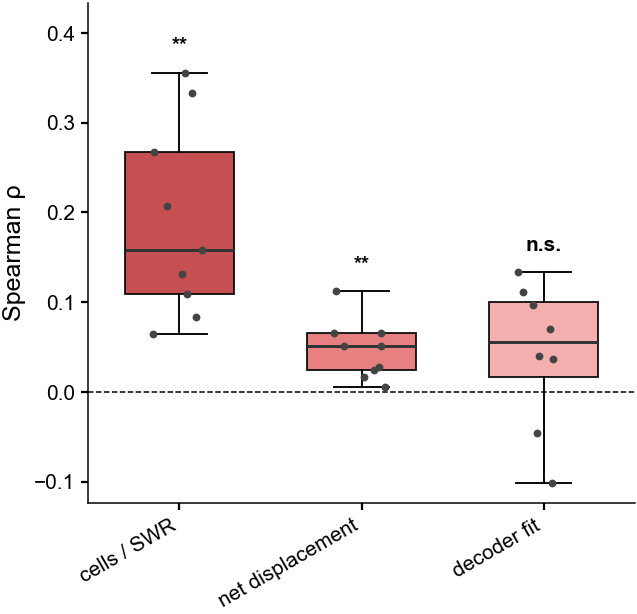

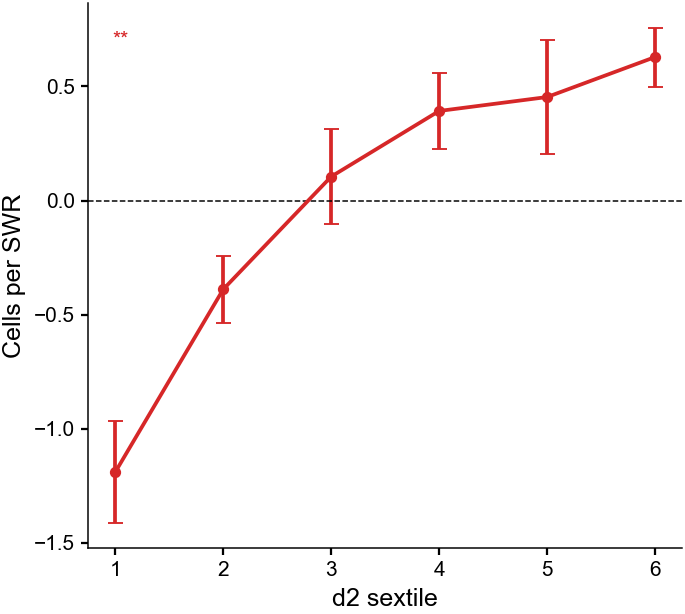

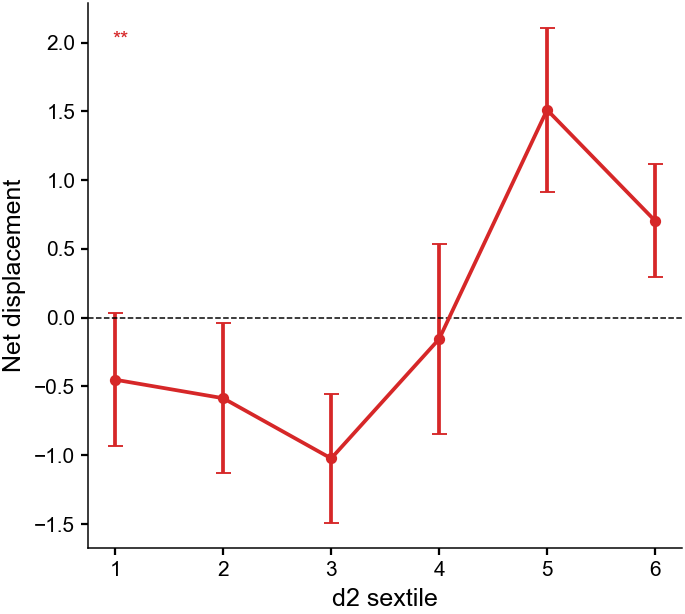

In [2]:
# a-c: the figure of fig2f_d2_replay_content.main (box_panel from fig2f_seat_ladders), its stars by F.stars,
# captured (nothing written) and cut into single panels at print size
S = producer("fig2f_seat_ladders_drawing")        # fig2f_seat_ladders.py's box_panel and stars (copied)
M = producer("fig2f_d2_replay_content_drawing")   # fig2f_d2_replay_content.py's main (copied)
S.stars = M.stars = F.stars
# ---- data (../csv) ----
W = read_csv("r35_replay_geometry_excised.csv")   # one row per decoded NREM window, 9 sessions
F7 = grab(lambda: M.draw_main(W), "fig2f_d2_replay_content")
# ---- the same from the recordings, with analysis_scripts/: ----
# sys.path.insert(0, os.path.join(F.REPO, "analysis_scripts", "revision"))
# S = producer("fig2f_seat_ladders"); M = producer("fig2f_d2_replay_content"); S.stars = M.stars = F.stars
# F7 = grab(M.main, "fig2f_d2_replay_content")   # main() reads r35_replay_geometry_excised.csv from its LOGDIR
panel(F7, 0, "FigS7_A_d2_replay_content_rho", 54, 52, ylabel="Spearman ρ")
panel(F7, 1, "FigS7_B_cells_per_swr", 58, 52, xlabel="d2 sextile", ylabel="Cells per SWR")
panel(F7, 2, "FigS7_C_net_displacement", 58, 52, xlabel="d2 sextile", ylabel="Net displacement")
plt.close(F7)
for name in ("FigS7_A_d2_replay_content_rho", "FigS7_B_cells_per_swr", "FigS7_C_net_displacement"):
    F.show(F.stem(name) + ".png")